In [2]:
import numpy as np
def f(x):
    return np.exp(-x) -x
def df(x):
    return -np.exp(-x) - 1

In [3]:
#Bisection
a, b = 0, 1

while abs(a-b)/2 > 1e-5:
    if f(a)*f(b) > 0:
        print('enter valid numbers')
        break
    c = (a + b)/2
    if f(a)*f(c) > 0:
        a = c
    else: b = c

root = (a+b)/2

print('root =', root)

root = 0.5671463012695312


In [4]:
#newton
x0 = 0

while abs(f(x0)) > 1e-5:
    x1 = x0 - f(x0)/df(x0)
    x0 = x1

print('newton root =', x0)

newton root = 0.5671431650348622


In [5]:
x0 = 0
x1 = 1

while abs(f(x1)) > 1e-5:
    d = (f(x1) - f(x0))/(x1-x0)
    x2 = x0 - f(x0)/d
    x0, x1 = x1, x2

print('secant root =', x1)

secant root = 0.5671433066049633


In [6]:
x = np.array([0, 0.5, 1])
while True:
    
    y = f(x)
    if abs(y[-1]) < 1e-5: break

    q = y[0]/y[1]
    r = y[2]/y[1]
    s = y[2]/y[0]

    x3 = x[2] - (r*(r-q)*(x[2]-x[1]) + s*(1-r)*(x[2]-x[0]))/((q-1)*(r-1)*(s-1))
    x[0], x[1], x[2] = x[1], x[2], x3

print(x[2])


0.5671432847571815


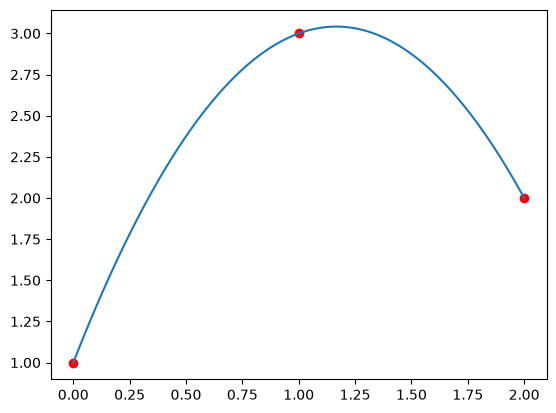

2.8673770864372115


In [7]:
x_pnts = np.array([0, 1, 2])
y_pnts = np.array([1, 3, 2])

x = np.linspace(0, 2, 200)
y = np.zeros_like(x)

for k in range(len(x)):
    L = 0
    for i in range(len(x_pnts)):
        prod = y_pnts[i]
        for j in range(len(x_pnts)):
            if i!=j:
                prod *= (x[k] - x_pnts[j])/(x_pnts[i] - x_pnts[j])
        L += prod
    y[k] = L

import matplotlib.pyplot as plt

plt.plot(x, y)
plt.scatter(x_pnts, y_pnts, marker='o', c='r')
plt.show() 
print(y[150])

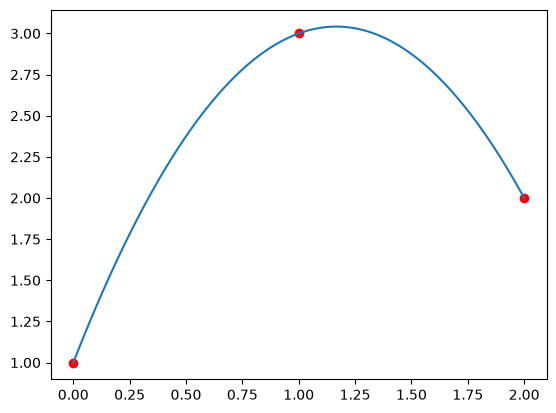

2.8673770864372106


In [8]:
#newton method

x_pnts = np.array([0, 1, 2])
y_pnts = np.array([1, 3, 2])

x = np.linspace(0, 2, 200)
y = np.zeros_like(x)

n = len(x_pnts)
coeff = np.zeros((n, n))
coeff[:, 0] = y_pnts

for j in range(1, n):
    for i in range(n - j):
        coeff[i][j] = (coeff[i+1][j-1] - coeff[i][j-1])/(x_pnts[i+j] - x_pnts[i])

c = coeff[0, :]

for i in range(len(x)):
    val = c[0]
    prod = 1
    for j in range(1, n):
        prod *= x[i] - x_pnts[j-1]
        val += prod*c[j]
    y[i] = val

plt.plot(x, y)
plt.scatter(x_pnts, y_pnts, marker='o', c='r')
plt.show()
print(y[150])

In [9]:
a, b = 0, np.pi
n = 40
def f(x): return np.sin(x)

# comp trap

h = (b-a)/n
x = np.linspace(a, b, n+1)
area = h*(f(x[0])+f(x[-1])+2*np.sum(f(x[1:-1])))/2
print(area)

1.9989718104970657


In [10]:
a, b = 0, np.pi
n = 40
def f(x): return np.sin(x)

# comp simp

h = (b-a)/n
x = np.linspace(a, b, n+1)
area = h*(f(x[0])+f(x[-1])+4*np.sum(f(x[1:-1:2])) + 2*np.sum(f(x[2:-1:2])))/3
print(area)

2.0000004230931827


In [11]:
a, b = 0, np.pi
n = 40
def f(x): return np.sin(x)

# comp simp

h = (b-a)/n
x = np.linspace(a+h/2, b-h/2, n)
area = h*np.sum(f(x[:]))
print(area)

2.0005141343946056


In [12]:
a, b = 0, np.pi
n = 4
def f(x): return np.sin(x)

# Gaussian Quad

t, c = np.polynomial.legendre.leggauss(n)

mapped = ((b-a)/2)*t + (b+a)/2

area = (b-a)*0.5*np.sum(c * f(mapped))
print(area)

1.9999842284577227


In [13]:
A = np.array([
    [ 3.0,  2.0, -1.0],
    [ 2.0, -2.0,  4.0],
    [-1.0,  0.5, -1.0]
])
b = np.array([1.0, -2.0, 0.0])

n = len(b)

for i in range(n):
    for j in range(i+1, n):
        factor = A[j, i]/A[i, i]
        A[j] -= factor*A[i]
        b[j] -= factor*b[i]
    
x = np.linalg.solve(A, b)
print(x)

[ 1. -2. -2.]


In [14]:
A = np.array([
    [ 3.0,  2.0, -1.0],
    [ 2.0, -2.0,  4.0],
    [-1.0,  0.5, -1.0]
])
b = np.array([1.0, -2.0, 0.0])

n = len(b)
L = np.eye(n)
U = A.copy()

for i in range(n):
    for j in range(i+1, n):
        factor = U[j, i]/U[i, i]
        U[j] -= factor*U[i]
        L[j][i] = factor
    
y = np.linalg.solve(L, b)
x = np.linalg.solve(U, y)
print(x)

[ 1. -2. -2.]


In [15]:
A = np.array([
    [ 3.0,  2.0, -1.0],
    [ 2.0, -2.0,  4.0],
    [-1.0,  0.5, -1.0]
])
b = np.array([1.0, -2.0, 0.0])

n = len(b)
L = np.eye(n)
P = np.eye(n)
U = A.copy()

for i in range(n):

    max_idx = np.argmax(np.abs(U[i:, i])) + i

    if i != max_idx:
        U[i], U[max_idx] = U[max_idx].copy(), U[i].copy
        P[i], P[max_idx] = P[max_idx].copy(), P[i].copy
        if i > 0:
            l[i, :i], l[max_idx, :i] = l[max_idx, :i].copy, l[i, :i]

    for j in range(i+1, n):
        factor = U[j, i]/U[i, i]
        U[j] -= factor*U[i]
        L[j][i] = factor
    
y = np.linalg.solve(L, P@b)
x = np.linalg.solve(U, y)
print(x)

[ 1. -2. -2.]


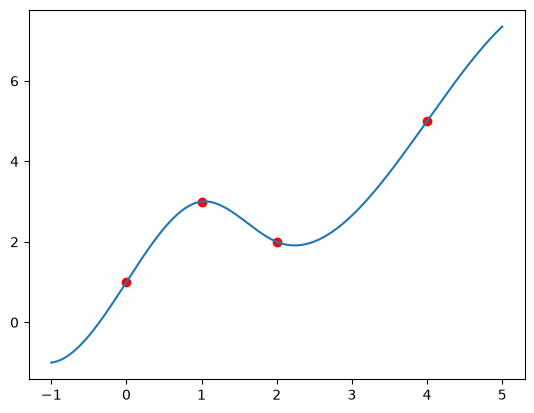

In [23]:
x_points = np.array([0.0, 1.0, 2.0, 4.0])
y_points = np.array([1.0, 3.0, 2.0, 5.0])

def compute_natural_cubic_spline(x, y):
    n = len(x)
    A = np.zeros((n, n))
    B = np.zeros(n)

    dx = np.diff(x)
    dy = np.diff(y)

    A[0,0] = 1
    A[n-1, n-1] = 1

    for i in range(1, n-1):
        A[i, i] = 2 * (dx[i] + dx[i-1])
        A[i, i-1] = dx[i-1]
        A[i, i+1] = dx[i]
        B[i] = 3 * (dy[i]/dx[i] - dy[i-1]/dx[i-1])

    c = np.linalg.solve(A, B)
    a = y[:-1]
    b = np.zeros(n-1)
    d = np.zeros(n-1)
    for i in range(n-1):
        d[i] = (c[i+1] - c[i])/(3*dx[i])
        b[i] = dy[i]/dx[i] - c[i]*dx[i] - d[i]*(dx[i]**2)
    
    return a, b, c[:-1], d

def evaluate_spline(x_dense, x_points, a, b, c, d):
    y_dense = []
    for x_val in x_dense:
        if x_val <= x_points[0]:
            i = 0
        elif x_val >= x_points[-2]:
            i = len(x_points) -2
        else:
            for i in range(len(x_points)-1):
                if x_points[i] <= x_val <= x_points[i+1]:
                    break
        dx = x_val - x_points[i]
        y_dense.append(a[i] + b[i]*dx + c[i]*dx**2 + d[i]*dx**3)
    return np.array(y_dense)




# Step 1: Extract polynomial coefficients
a, b, c, d = compute_natural_cubic_spline(x_points, y_points)

# Step 2: Evaluate on a dense grid for smooth plotting
x_dense = np.linspace(-1, 5, 200)
y_dense = evaluate_spline(x_dense, x_points, a, b, c, d)

plt.plot(x_dense, y_dense)
plt.scatter(x_points, y_points, marker='o', c='r')
plt.show()